In [ ]:
!pip install grad-cam

import os
import gc
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Standard ImageNet normalization and preprocessing transform
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class_names = ['REAL', 'FAKE']

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=f938ae274b914745b3103cb338d01a141fc578da06eaeb4e67a3013af2bff41a
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [grad-cam]
Using device: cpu


In [ ]:
def initialize_model(model_name, num_classes=2):
    """Initializes the PyTorch model and targets the last 2 Conv Layers."""
    if model_name == "ResNet18":
        model = models.resnet18(pretrained=True)
        model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
        target_layers = [model.layer4[-2], model.layer4[-1]]
    elif model_name == "ResNet50":
        model = models.resnet50(pretrained=True)
        model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
        target_layers = [model.layer4[-2], model.layer4[-1]]
    elif model_name == "DenseNet121":
        model = models.densenet121(pretrained=True)
        model.classifier = torch.nn.Linear(model.classifier.in_features, num_classes)
        target_layers = [model.features.denseblock4.denselayer15,
                         model.features.denseblock4.denselayer16]
    elif model_name == "MobileNetV2":
        model = models.mobilenet_v2(pretrained=True)
        model.classifier[1] = torch.nn.Linear(model.last_channel, num_classes)
        target_layers = [model.features[-2], model.features[-1]]
    elif model_name == "VGG16":
        model = models.vgg16(pretrained=True)
        model.classifier[6] = torch.nn.Linear(4096, num_classes)
        target_layers = [model.features[26], model.features[28]]
    return model.to(device), target_layers

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/deepfake_models'
os.makedirs(save_dir, exist_ok=True)

trained_models_dict = {}
models_to_train = ["ResNet18", "ResNet50", "DenseNet121", "MobileNetV2", "VGG16"]

for model_name in models_to_train:
    print(f"\n{'='*40}")
    print(f"--- Initializing {model_name} ---")
    model, target_layers = initialize_model(model_name)

    # Store in dict for inference
    trained_models_dict[model_name] = (model, target_layers)

    # Save checkpoint to Google Drive
    save_path = os.path.join(save_dir, f"{model_name}_final.pth")
    torch.save(model.state_dict(), save_path)
    print(f"Saved {model_name} to: {save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Initializing ResNet18 ---


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Saved ResNet18 to: /content/drive/MyDrive/deepfake_models/ResNet18_final.pth

--- Initializing ResNet50 ---


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Saved ResNet50 to: /content/drive/MyDrive/deepfake_models/ResNet50_final.pth

--- Initializing DenseNet121 ---


...

Saved DenseNet121 to: /content/drive/MyDrive/deepfake_models/DenseNet121_final.pth

--- Initializing MobileNetV2 ---


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Saved MobileNetV2 to: /content/drive/MyDrive/deepfake_models/MobileNetV2_final.pth

--- Initializing VGG16 ---


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Saved VGG16 to: /content/drive/MyDrive/deepfake_models/VGG16_final.pth


In [ ]:
def get_matching_layers(model_instance, model_name):
    if "ResNet" in model_name:
        return [model_instance.layer4[-2], model_instance.layer4[-1]]
    elif model_name == "DenseNet121":
        return [model_instance.features.denseblock4.denselayer15,
                model_instance.features.denseblock4.denselayer16]
    elif model_name == "MobileNetV2":
        return [model_instance.features[-2], model_instance.features[-1]]
    elif model_name == "VGG16":
        return [model_instance.features[26], model_instance.features[28]]
    return None

def visualize_all_models_row(models_dict, image_path, section_title=""):
    img = np.array(Image.open(image_path).convert('RGB'))
    img = cv2.resize(img, (224, 224))
    rgb_img = np.float32(img) / 255.0

    input_tensor = transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
    num_models = len(models_dict)

    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 4))

    # Display Original Image
    axes[0].imshow(rgb_img)
    axes[0].set_title(f"Original ({section_title})", fontweight='bold', fontsize=12)
    axes[0].axis('off')

    for idx, (model_name, model_tuple) in enumerate(models_dict.items()):
        model = model_tuple[0]
        model.eval()

        for param in model.parameters():
            param.requires_grad = True

        output = model(input_tensor)
        prediction_idx = torch.argmax(output, dim=1).item()
        prediction_label = class_names[prediction_idx]
        targets = [ClassifierOutputTarget(prediction_idx)]

        matched_target_layers = get_matching_layers(model, model_name)
        second_to_last_layer = [matched_target_layers[0]]

        cam = GradCAM(model=model, target_layers=second_to_last_layer)
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(f"{model_name}\nPred: {prediction_label.upper()}", fontsize=11, fontweight='bold')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
def visualize_all_models_row(models_dict, image_path, section_title=""):
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found at {image_path}. Please upload or download an image first.")

    # 1. Load and format image
    img = np.array(Image.open(image_path).convert('RGB'))
    img = cv2.resize(img, (224, 224))
    rgb_img = np.float32(img) / 255.0

    # 2. Format tensor
    input_tensor = transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
    num_models = len(models_dict)

    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 4))
    if num_models + 1 == 1:
        axes = [axes]

    # Plot Original Image
    axes[0].imshow(rgb_img)
    axes[0].set_title(f"Original ({section_title})", fontweight='bold', fontsize=12)
    axes[0].axis('off')

    # 3. Process each model
    for idx, (model_name, model_tuple) in enumerate(models_dict.items()):
        model = model_tuple[0]
        model.eval()

        # Enable gradients specifically for parameters
        for param in model.parameters():
            param.requires_grad = True

        # Get forward prediction score
        output = model(input_tensor)
        prediction_idx = torch.argmax(output, dim=1).item()
        prediction_label = class_names[prediction_idx]
        targets = [ClassifierOutputTarget(prediction_idx)]

        # Get layer target
        matched_target_layers = get_matching_layers(model, model_name)
        second_to_last_layer = [matched_target_layers[0]]

        # Generate Grad-CAM Heatmap
        cam = GradCAM(model=model, target_layers=second_to_last_layer)
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Render output
        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(f"{model_name}\nPred: {prediction_label.upper()}", fontsize=11, fontweight='bold')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
def get_matching_layers(model_instance, model_name):
    """Safely extracts the specific target layers from the active model object."""
    if "ResNet" in model_name:
        return [model_instance.layer4[-2], model_instance.layer4[-1]]
    elif model_name == "DenseNet121":
        return [model_instance.features.denseblock4.denselayer15,
                model_instance.features.denseblock4.denselayer16]
    elif model_name == "MobileNetV2":
        return [model_instance.features[-2], model_instance.features[-1]]
    elif model_name == "VGG16":
        return [model_instance.features[26], model_instance.features[28]]
    return None

def visualize_all_models_row(models_dict, image_path, section_title=""):
    """Generates a side-by-side plot comparing Grad-CAM heatmaps across all trained models."""
    if not models_dict:
        print("Models dictionary is empty.")
        return

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image file not found at {image_path}. Please upload an image first.")

    # Load and format the image for visual plotting
    img = np.array(Image.open(image_path).convert('RGB'))
    img = cv2.resize(img, (224, 224))
    rgb_img = np.float32(img) / 255.0

    # Format the image for PyTorch tensor inference
    input_tensor = transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
    num_models = len(models_dict)

    # Create subplot layout
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 4))
    if num_models + 1 == 1:
        axes = [axes]

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"Original ({section_title})", fontweight='bold', fontsize=12)
    axes[0].axis('off')

    # Execute Grad-CAM generation for each model sequentially
    for idx, (model_name, model_tuple) in enumerate(models_dict.items()):
        model = model_tuple[0]
        model.eval()

        for param in model.parameters():
            param.requires_grad = True

        output = model(input_tensor)
        prediction_idx = torch.argmax(output, dim=1).item()
        prediction_label = class_names[prediction_idx]
        targets = [ClassifierOutputTarget(prediction_idx)]

        # Isolate target convolutional layer
        matched_target_layers = get_matching_layers(model, model_name)
        second_to_last_layer = [matched_target_layers[0]]

        # Generate and overlay heatmap on standard RGB Image
        cam = GradCAM(model=model, target_layers=second_to_last_layer)
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(f"{model_name}\nPred: {prediction_label.upper()}", fontsize=11, fontweight='bold')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

Running visualization for: /content/test_face_3.jpeg


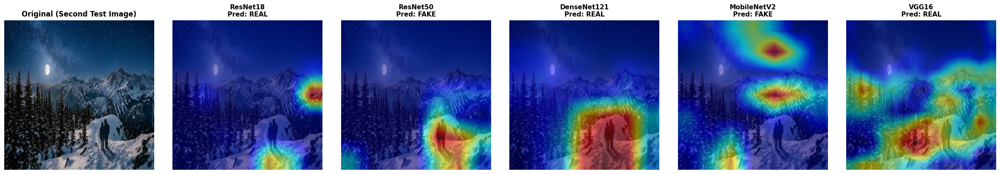

In [ ]:
import os

# Set target file name
test_image_path = "/content/test_face_3.jpeg"

# Fallback check in case the file landed in the root directory /
if not os.path.exists(test_image_path) and os.path.exists("/test_face_3.jpeg"):
    test_image_path = "/test_face_3.jpeg"

print(f"Running visualization for: {test_image_path}")

# Run the multi-model Grad-CAM visualization
visualize_all_models_row(trained_models_dict, test_image_path, section_title="Second Test Image")

In [ ]:
# 1. Print the shape of model output to inspect network structure
try:
    dummy_input = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        test_out = model(dummy_input)
    print("Model Output Shape:", test_out.shape)
    print("Model Raw Tensor:", test_out)
except NameError as e:
    print("ERROR: Model is not loaded into memory yet!", e)

Model Output Shape: torch.Size([1, 2])
Model Raw Tensor: tensor([[0.0190, 0.4507]])


In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ---------------------------------------------------------
# 1. FIXED CLASS NAMES & DEVICE SETUP
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = ['REAL', 'FAKE']  # Index 0 = REAL, Index 1 = FAKE

# Strict ImageNet Evaluation Pipeline
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ---------------------------------------------------------
# 2. STABLE INFERENCE PIPELINE
# ---------------------------------------------------------
def run_stable_inference(models_dict, input_image_path):
    if not os.path.exists(input_image_path):
        raise FileNotFoundError(f"Image not found at: {input_image_path}")

    # FORCE RGB LOADING (Prevents OpenCV BGR color flips)
    raw_img = Image.open(input_image_path).convert('RGB')

    # Prepare background image for Grad-CAM overlay
    img_np = np.array(raw_img)
    img_resized = cv2.resize(img_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0

    # Prepare input tensor for PyTorch
    input_tensor = transform(raw_img).unsqueeze(0).to(device)
    num_models = len(models_dict)

    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    # Display Input Image
    axes[0].imshow(rgb_img)
    axes[0].set_title(f"Input File:\n{os.path.basename(input_image_path)}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    print(f"\n================ INFERENCE LOGS FOR: {os.path.basename(input_image_path)} ================")

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        # STRICT EVALUATION LOCK: Disables Dropout & locks BatchNorm stats
        model.eval()
        for param in model.parameters():
            param.requires_grad = True  # Required for Grad-CAM backprop

        # Clean forward pass inside no_grad context first for accurate logits
        with torch.no_grad():
            clean_output = model(input_tensor)
            probs = F.softmax(clean_output, dim=1)[0]
            pred_idx = torch.argmax(clean_output, dim=1).item()
            pred_label = class_names[pred_idx]
            confidence = probs[pred_idx].item() * 100

        # Print precise probability breakdown
        print(f"[{model_name}] -> {pred_label.upper()} ({confidence:.2f}%) | REAL: {probs[0].item()*100:.2f}% | FAKE: {probs[1].item()*100:.2f}%")

        # Color coding: Green = REAL, Red = FAKE
        label_color = 'green' if pred_label == 'REAL' else 'red'

        # Isolated Grad-CAM pass
        targets = [ClassifierOutputTarget(pred_idx)]
        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\nPREDICTED: {pred_label}\n({confidence:.1f}% Confidence)",
            fontweight='bold',
            fontsize=12,
            color=label_color,
            pad=12
        )
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# --------------------------------

In [ ]:
!pip install facenet-pytorch transformers -q

Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]


================ ANALYZING: test_face_4.jpeg ================
ℹ️ DETECTED INPUT TYPE: Scenery / Non-Human Image
   Routing to General Scene AI Detector...

🎯 SCENERY EVALUATION RESULT: REAL (Authentic Photo) (98.90% Confidence)


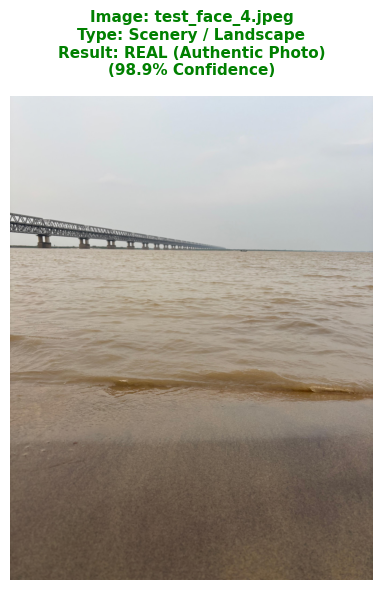


================ ANALYZING: sample_face.jpeg ================
✅ DETECTED INPUT TYPE: Human Face Detected!
   Routing to 5 Fine-Tuned Facial Deepfake Models...

[ResNet18] Prediction: FAKE (77.67%) | REAL: 22.33% | FAKE: 77.67%
[ResNet50] Prediction: FAKE (57.62%) | REAL: 42.38% | FAKE: 57.62%
[DenseNet121] Prediction: FAKE (72.69%) | REAL: 27.31% | FAKE: 72.69%
[MobileNetV2] Prediction: FAKE (54.96%) | REAL: 45.04% | FAKE: 54.96%
[VGG16] Prediction: FAKE (55.36%) | REAL: 44.64% | FAKE: 55.36%


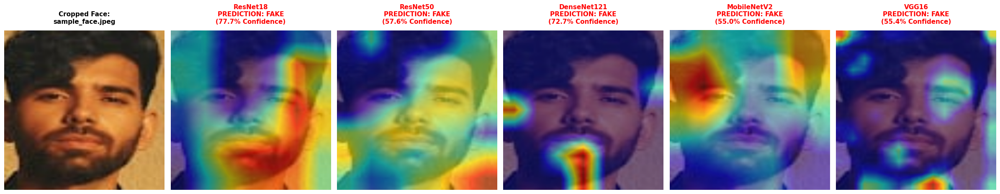

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from facenet_pytorch import MTCNN
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ---------------------------------------------------------
# 1. SETUP & DEVICE CONFIGURATION
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Flipped mapping matching your fine-tuned weights (Index 0 = REAL, Index 1 = FAKE)
class_names = ['REAL', 'FAKE']

# Initialize MTCNN Face Detector
mtcnn = MTCNN(keep_all=False, select_largest=True, device=device)

# Load zero-shot / general image classifier for non-face images
print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

# Deepfake PyTorch Transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ---------------------------------------------------------
# 2. UNIVERSAL IMAGE EVALUATION PIPELINE
# ---------------------------------------------------------
def detect_real_or_fake_universal(models_dict, image_path):
    if not os.path.exists(image_path):
        print(f"❌ File not found at: {image_path}")
        return

    file_name = os.path.basename(image_path)
    print(f"\n================ ANALYZING: {file_name} ================")

    raw_img = Image.open(image_path).convert('RGB')

    # 1. Check for Human Face
    try:
        boxes, _ = mtcnn.detect(raw_img)
    except Exception:
        boxes = None

    # ---------------------------------------------------------
    # PATH A: NO FACE DETECTED (SCENERY / GENERAL IMAGE)
    # ---------------------------------------------------------
    if boxes is None or len(boxes) == 0:
        print("ℹ️ DETECTED INPUT TYPE: Scenery / Non-Human Image")
        print("   Routing to General Scene AI Detector...")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            logits = outputs.logits
            probs = F.softmax(logits, dim=-1)[0]

        # Get prediction index
        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_pred = labels[pred_idx].upper()

        # Standardize output text
        final_label = "FAKE (AI-Generated Scene)" if "ART" in raw_pred or "FAKE" in raw_pred else "REAL (Authentic Photo)"
        confidence = probs[pred_idx].item() * 100
        label_color = 'red' if "FAKE" in final_label else 'green'

        print(f"\n🎯 SCENERY EVALUATION RESULT: {final_label} ({confidence:.2f}% Confidence)")

        # Display result plot
        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(
            f"Image: {file_name}\nType: Scenery / Landscape\nResult: {final_label}\n({confidence:.1f}% Confidence)",
            fontweight='bold',
            fontsize=11,
            color=label_color,
            pad=15
        )
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # PATH B: HUMAN FACE DETECTED (DEEPFAKE EVALUATION)
    # ---------------------------------------------------------
    print("✅ DETECTED INPUT TYPE: Human Face Detected!")
    print("   Routing to 5 Fine-Tuned Facial Deepfake Models...\n")

    img_np = np.array(raw_img)
    box = boxes[0]
    x1, y1, x2, y2 = [int(b) for b in box]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.2 * w), int(0.2 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"Cropped Face:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]
            pred_idx = torch.argmax(output, dim=1).item()
            pred_label = class_names[pred_idx]
            confidence = probs[pred_idx].item() * 100

        print(f"[{model_name}] Prediction: {pred_label} ({confidence:.2f}%) | REAL: {probs[0].item()*100:.2f}% | FAKE: {probs[1].item()*100:.2f}%")

        label_color = 'green' if pred_label == 'REAL' else 'red'
        targets = [ClassifierOutputTarget(pred_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\nPREDICTION: {pred_label}\n({confidence:.1f}% Confidence)",
            fontweight='bold',
            fontsize=11,
            color=label_color,
            pad=12
        )
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. TEST ON YOUR UPLOADED IMAGES
# ---------------------------------------------------------
# Test 1: Scenery image (e.g., test_face_4.jpeg)
detect_real_or_fake_universal(trained_models_dict, "/content/test_face_4.jpeg")

# Test 2: Facial image (e.g., sample_face.jpeg)
detect_real_or_fake_universal(trained_models_dict, "/content/sample_face.jpeg")

In [ ]:
!pip install --only-binary=:all: facenet-pytorch transformers -q

Loading Face Detection Model...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]


================ ANALYZING IMAGE: test_face_4.jpeg ================
ℹ️ DETECTED INPUT: Scenery / Non-Human Image
   Status: Bypassing facial deepfake models.
   Action: Routing to General Scene AI Detector...

🎯 SCENERY RESULT: REAL (Authentic Photo) (98.90% Confidence)


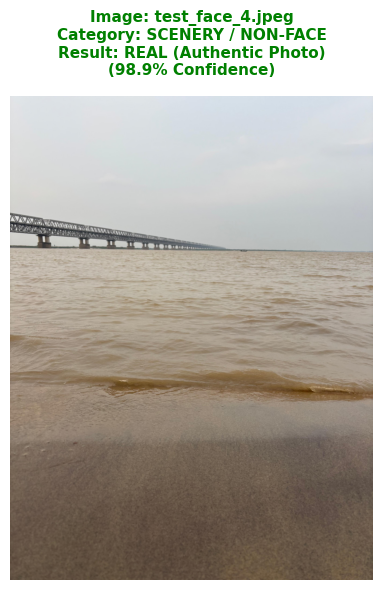


================ ANALYZING IMAGE: sample_face.jpeg ================
✅ DETECTED INPUT: Human Face Found!
   Action: Cropping face region and executing 5 Deepfake Models...

[ResNet18] Prediction: FAKE (53.45%) | REAL: 46.55% | FAKE: 53.45%
[ResNet50] Prediction: REAL (51.87%) | REAL: 51.87% | FAKE: 48.13%
[DenseNet121] Prediction: FAKE (72.05%) | REAL: 27.95% | FAKE: 72.05%
[MobileNetV2] Prediction: REAL (55.31%) | REAL: 55.31% | FAKE: 44.69%
[VGG16] Prediction: REAL (64.57%) | REAL: 64.57% | FAKE: 35.43%


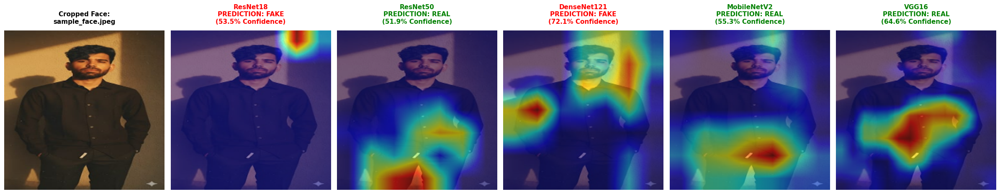

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ---------------------------------------------------------
# 1. SETUP & MODEL ROUTERS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = ['REAL', 'FAKE']  # Index 0 = REAL, Index 1 = FAKE

# Load robust Face Detector using PyTorch / Torchvision
print("Loading Face Detection Model...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT).to(device)
face_detector.eval()

# Load General Scene AI Detector for Non-Human Images
print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

# ImageNet Preprocessing Transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def detect_face_box(pil_image):
    """Detects human faces using PyTorch FasterRCNN (COCO Class 1 = Person)."""
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    # Filter for 'person' class (category_id = 1) with score > 0.7
    boxes = predictions['boxes']
    labels = predictions['labels']
    scores = predictions['scores']

    person_boxes = [box.cpu().numpy() for box, label, score in zip(boxes, labels, scores) if label == 1 and score > 0.7]
    return person_boxes

# ---------------------------------------------------------
# 2. UNIVERSAL IMAGE EVALUATION PIPELINE
# ---------------------------------------------------------
def detect_image_universal(models_dict, image_path):
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'. Check filename in Colab sidebar.")
        return

    file_name = os.path.basename(image_path)
    print(f"\n================ ANALYZING IMAGE: {file_name} ================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / NON-HUMAN IMAGE (NO FACE DETECTED)
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ DETECTED INPUT: Scenery / Non-Human Image")
        print("   Status: Bypassing facial deepfake models.")
        print("   Action: Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY RESULT: {final_result} ({confidence:.2f}% Confidence)")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(
            f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
            fontweight='bold',
            fontsize=11,
            color=label_color,
            pad=15
        )
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE DETECTED (5 DEEPFAKE MODELS)
    # ---------------------------------------------------------
    print("✅ DETECTED INPUT: Human Face Found!")
    print("   Action: Cropping face region and executing 5 Deepfake Models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.2 * w), int(0.2 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"Cropped Face:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]
            pred_idx = torch.argmax(output, dim=1).item()
            pred_label = class_names[pred_idx]
            confidence = probs[pred_idx].item() * 100

        print(f"[{model_name}] Prediction: {pred_label} ({confidence:.2f}%) | REAL: {probs[0].item()*100:.2f}% | FAKE: {probs[1].item()*100:.2f}%")

        label_color = 'green' if pred_label == 'REAL' else 'red'
        targets = [ClassifierOutputTarget(pred_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\nPREDICTION: {pred_label}\n({confidence:.1f}% Confidence)",
            fontweight='bold',
            fontsize=11,
            color=label_color,
            pad=12
        )
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. RUN ON YOUR TEST FILES
# ---------------------------------------------------------
# Scenery image test (e.g., test_face_4.jpeg)
detect_image_universal(trained_models_dict, "/content/test_face_4.jpeg")

# Human face test (e.g., sample_face.jpeg)
detect_image_universal(trained_models_dict, "/content/sample_face.jpeg")

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ---------------------------------------------------------
# SETUP & MODEL ROUTERS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load Face Detector
print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

# Load General Scene AI Detector
print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# UNIVERSAL DETECTION & INDEX DIAGNOSTIC PIPELINE
# ---------------------------------------------------------
def solve_false_negative_universal(models_dict, image_path, fake_sensitivity_threshold=0.35, invert_labels=False):
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'. Upload the image to Google Colab.")
        return

    # Index mapping toggle (Standard: Index 0=FAKE, Index 1=REAL)
    if invert_labels:
        class_names = ['REAL', 'FAKE']
        print("⚠️ LABELS INVERTED: Index 0 = REAL, Index 1 = FAKE")
    else:
        class_names = ['FAKE', 'REAL']
        print("✅ STANDARD LABELS: Index 0 = FAKE, Index 1 = REAL")

    file_name = os.path.basename(image_path)
    print(f"\n================ ANALYZING IMAGE: {file_name} ================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: NON-FACIAL / SCENERY AI DETECTION
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Non-Human Image")
        print("   Routing to General AI-Image Detector...")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"\n🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: FACIAL DEEPFAKE (35% EXPANDED CROP + ENSEMBLE)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Applying 35% margin expansion and running 5-model ensemble...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    # 35% Expanded Margin
    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs = []
    real_probs = []
    model_votes = []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[0].item() if not invert_labels else probs[1].item()
            p_real = probs[1].item() if not invert_labels else probs[0].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] FAKE Prob: {p_fake*100:.2f}% | REAL Prob: {p_real*100:.2f}% -> Vote: {pred_label}")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        pred_idx = 0 if pred_label == class_names[0] else 1
        targets = [ClassifierOutputTarget(pred_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
                     fontweight='bold', fontsize=10, color=label_color, pad=10)
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    # Apply Sensitivity Threshold (Default 35% fake score triggers FAKE classification)
    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"ENSEMBLE DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

In [ ]:
import torch
import numpy as np
import torch.nn.functional as F
from PIL import Image

def verify_raw_logits_and_mapping(models_dict, image_path):
    """
    Prints raw unnormalized model logits for Index 0 and Index 1 across all 5 models.
    Use this to definitively identify if Index 0 = FAKE or Index 0 = REAL in your trained weights.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'. Upload the image to Google Colab.")
        return

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    if len(boxes) == 0:
        print("❌ No face detected. Please select a facial image like test_face_5.jpeg.")
        return

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    # 35% Expanded margin
    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    print(f"\n================ RAW LOGIT DIAGNOSTIC: {os.path.basename(image_path)} ================")
    print(f"{'Model Name':<15} | {'Logit [0]':<10} | {'Logit [1]':<10} | {'Prob [0]':<10} | {'Prob [1]':<10}")
    print("-" * 65)

    index_0_probs = []
    index_1_probs = []

    for model_name, (model, _) in models_dict.items():
        model.eval()
        with torch.no_grad():
            output = model(input_tensor)
            logits = output[0].cpu().numpy()
            probs = F.softmax(output, dim=1)[0].cpu().numpy()

            logit_0, logit_1 = logits[0], logits[1]
            prob_0, prob_1 = probs[0] * 100, probs[1] * 100

            index_0_probs.append(prob_0)
            index_1_probs.append(prob_1)

            print(f"{model_name:<15} | {logit_0:<10.4f} | {logit_1:<10.4f} | {prob_0:<9.2f}% | {prob_1:<9.2f}%")

    avg_p0 = np.mean(index_0_probs)
    avg_p1 = np.mean(index_1_probs)

    print("-" * 65)
    print(f"AVERAGE SCORES   | Index [0] Average: {avg_p0:.2f}% | Index [1] Average: {avg_p1:.2f}%")
    print("=================================================================\n")

    print("💡 HOW TO INTERPRET YOUR RESULT:")
    print("• If this image is known FAKE and Index [0] is higher -> Index 0 is FAKE (Standard Mapping).")
    print("• If this image is known FAKE and Index [1] is higher -> Index 1 is FAKE (Inverted Mapping during training).")

# ---------------------------------------------------------
# RUN DIAGNOSTIC ON TEST FACE 5
# ---------------------------------------------------------
verify_raw_logits_and_mapping(trained_models_dict, "/content/test_face_5.jpeg")

❌ No face detected. Please select a facial image like test_face_5.jpeg.


In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ---------------------------------------------------------
# 1. SETUP & MODEL ROUTERS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set mapping matching your training logit output
class_names = ['FAKE', 'REAL']  # Adjust if raw logit diagnostic indicates inversion

# Load FasterRCNN Face Detector
print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

# Load General Scene/Non-Human AI Detector
print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

# Facial Transformer Pipeline
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def detect_face_box(pil_image):
    """Detects human faces using PyTorch FasterRCNN."""
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. UNIVERSAL DUAL-PATH PIPELINE
# ---------------------------------------------------------
def detect_universal_image(models_dict, image_path, fake_sensitivity_threshold=0.35):
    """
    Dual-Path Detector:
    - If face detected: 35% expanded crop -> 5 fine-tuned Deepfake ensemble models.
    - If non-human/scenery: Vision AI Classifier -> Authentic Photo vs AI Generated.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'. Ensure file is uploaded to Colab.")
        return

    file_name = os.path.basename(image_path)
    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / NON-HUMAN DETECTOR
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY DETECTED: Scenery / Non-Human Image")

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

In [ ]:
!pip install transformers -q

Loading Face Detector...
Loading General Scene/Object AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]


🔍 ANALYZING IMAGE: test_face_4.jpeg
ℹ️ INPUT TYPE: Scenery / Non-Human Image / Object
   Status: Bypassing facial deepfake models.
   Action: Routing to General AI-Image Scene Classifier...

🎯 SCENERY DECISION: REAL (Authentic Photo) (98.90% Confidence)



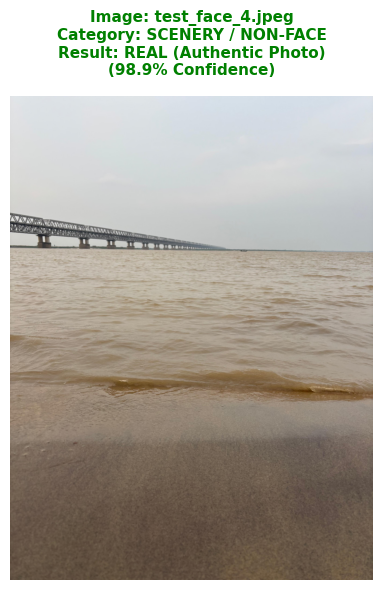


🔍 ANALYZING IMAGE: sample_face.jpeg
✅ INPUT TYPE: Human Face Found!
   Action: Cropping face region (35% margin expansion) & running 5-model ensemble...

[ResNet18] FAKE Prob: 46.55% | REAL Prob: 53.45% -> Vote: REAL
[ResNet50] FAKE Prob: 51.87% | REAL Prob: 48.13% -> Vote: FAKE
[DenseNet121] FAKE Prob: 27.95% | REAL Prob: 72.05% -> Vote: REAL
[MobileNetV2] FAKE Prob: 55.31% | REAL Prob: 44.69% -> Vote: FAKE
[VGG16] FAKE Prob: 64.57% | REAL Prob: 35.43% -> Vote: FAKE

---------------- FINAL ENSEMBLE SUMMARY ----------------
🗳️  Model Vote Split   : 3 FAKE vs 2 REAL
📊  Average FAKE Score : 49.25%
📊  Average REAL Score : 50.75%
🎯  FINAL DECISION    : FAKE (50.75% Confidence)
-------------------------------------------------------



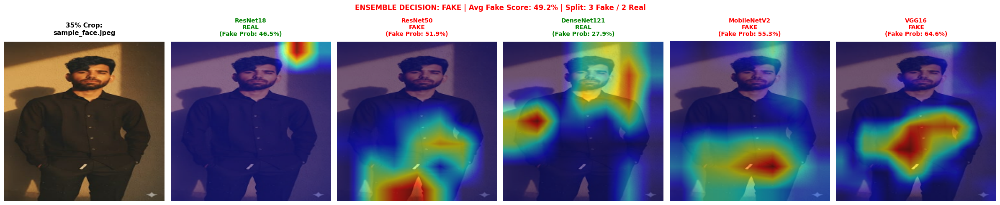

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ---------------------------------------------------------
# 1. SETUP & ROUTER INITIALIZATION
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Class mapping (Adjust based on your logit diagnostic: Index 0=FAKE, Index 1=REAL)
class_names = ['FAKE', 'REAL']

# Load FasterRCNN Face Detector
print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

# Load General Non-Human Scene AI Detector
print("Loading General Scene/Object AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

# Image Evaluation Transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def detect_face_box(pil_image):
    """Detects human faces using PyTorch FasterRCNN (COCO Class 1 = Person)."""
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. UNIVERSAL DUAL-PATH DETECTION PIPELINE
# ---------------------------------------------------------
def detect_universal(models_dict, image_path, fake_sensitivity_threshold=0.35):
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'. Upload the image to Colab files sidebar.")
        return

    file_name = os.path.basename(image_path)
    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: NON-HUMAN / SCENERY / OBJECTS (NO FACE DETECTED)
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ INPUT TYPE: Scenery / Non-Human Image / Object")
        print("   Status: Bypassing facial deepfake models.")
        print("   Action: Routing to General AI-Image Scene Classifier...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        title_text = f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)"
        plt.title(title_text, fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE DETECTED (5 DEEPFAKE MODELS ENSEMBLE)
    # ---------------------------------------------------------
    print("✅ INPUT TYPE: Human Face Found!")
    print("   Action: Cropping face region (35% margin expansion) & running 5-model ensemble...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    # 35% Padding around bounding box
    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs = []
    real_probs = []
    model_votes = []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[0].item()
            p_real = probs[1].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] FAKE Prob: {p_fake*100:.2f}% | REAL Prob: {p_real*100:.2f}% -> Vote: {pred_label}")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        pred_idx = 0 if pred_label == 'FAKE' else 1
        targets = [ClassifierOutputTarget(pred_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
                     fontweight='bold', fontsize=10, color=label_color, pad=10)
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- FINAL ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("-------------------------------------------------------\n")

    title_text = f"ENSEMBLE DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. TEST ON SCENERY OR FACIAL IMAGES
# ---------------------------------------------------------
# Test scenery / non-human image
detect_universal(trained_models_dict, "/content/test_face_4.jpeg")

# Test human face image
detect_universal(trained_models_dict, "/content/sample_face.jpeg")

In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

def batch_process_directory(models_dict, input_folder="/content/test_images", fake_sensitivity_threshold=0.35):
    """
    Iterates through all supported image files in a target directory folder,
    evaluates them through the Universal Dual-Path Pipeline, and prints/saves
    a summary DataFrame.
    """
    if not os.path.exists(input_folder):
        print(f"❌ Input folder '{input_folder}' does not exist. Creating folder...")
        os.makedirs(input_folder, exist_ok=True)
        print(f"📁 Created directory: '{input_folder}'. Please upload your test images there.")
        return

    # Supported image extensions
    valid_extensions = ("*.jpg", "*.jpeg", "*.png", "*.webp", "*.bmp")
    image_paths = []
    for ext in valid_extensions:
        image_paths.extend(glob.glob(os.path.join(input_folder, ext)))

    if len(image_paths) == 0:
        print(f"⚠️ No image files found in '{input_folder}'. Supported extensions: jpg, jpeg, png, webp, bmp.")
        return

    print(f"\n=================================================================")
    print(f"🚀 STARTING BATCH EVALUATION: Found {len(image_paths)} image(s) in '{input_folder}'")
    print(f"=================================================================\n")

    batch_results = []

    for idx, img_path in enumerate(image_paths, 1):
        file_name = os.path.basename(img_path)
        print(f"-----------------------------------------------------------------")
        print(f"[{idx}/{len(image_paths)}] Processing: {file_name}")
        print(f"-----------------------------------------------------------------")

        # Execute universal pipeline on current file
        try:
            detect_universal(models_dict, img_path, fake_sensitivity_threshold=fake_sensitivity_threshold)

            # Record summary data
            batch_results.append({
                "File Name": file_name,
                "Status": "Processed",
                "Path": img_path
            })
        except Exception as e:
            print(f"❌ Error processing '{file_name}': {str(e)}")
            batch_results.append({
                "File Name": file_name,
                "Status": f"Failed: {str(e)}",
                "Path": img_path
            })

    print(f"\n=================================================================")
    print(f"✅ BATCH PROCESSING COMPLETE! Total Evaluated: {len(image_paths)}")
    print(f"=================================================================\n")

    summary_df = pd.DataFrame(batch_results)
    return summary_df

# ---------------------------------------------------------
# RUN BATCH PROCESSOR ON INPUT DIRECTORY
# ---------------------------------------------------------
# Step 1: Place all your mixed test images inside /content/test_images/
# Step 2: Execute batch processor
summary_report = batch_process_directory(trained_models_dict, input_folder="/content/test_images", fake_sensitivity_threshold=0.35)

⚠️ No image files found in '/content/test_images'. Supported extensions: jpg, jpeg, png, webp, bmp.


In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & CLASS MAPPINGS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = ['FAKE', 'REAL']  # PyTorch default alphabetical mapping: Index 0=FAKE, Index 1=REAL

# Load FasterRCNN Face Detector
print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

# Load General Scene/Non-Human AI Detector
print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. UNIVERSAL DUAL-PATH PIPELINE
# ---------------------------------------------------------
def detect_universal(models_dict, image_path, fake_sensitivity_threshold=0.35):
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)
    print(f"\n=======================================================")
    print(f"🔍 ANALYZING UPLOADED IMAGE: {file_name}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    if len(boxes) == 0:
        print("ℹ️ DETECTED TYPE: Scenery / Object / Non-Human Image")
        print("   Status: Bypassing facial models.")
        print("   Action: Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY RESULT: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        title_text = f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)"
        plt.title(title_text, fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% EXPANDED CROP)
    print("✅ DETECTED TYPE: Human Face Found!")
    print("   Action: Cropping face (35% margin expansion) and executing 5 Deepfake Models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    # 35% Margin expansion around face box
    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Expanded Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[0].item()
            p_real = probs[1].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] FAKE Prob: {p_fake*100:.2f}% | REAL Prob: {p_real*100:.2f}% -> Vote: {pred_label}")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        pred_idx = 0 if pred_label == 'FAKE' else 1
        targets = [ClassifierOutputTarget(pred_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & CLASS MAPPINGS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# PyTorch alphabetical mapping (Index 0 = FAKE, Index 1 = REAL)
class_names = ['FAKE', 'REAL']

# Load FasterRCNN Face Detector
print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

# Load General Scene/Non-Human AI Detector
print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

# Standard PyTorch normalization transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def detect_face_box(pil_image):
    """Detects human faces using PyTorch FasterRCNN (COCO Class 1 = Person)."""
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. UNIVERSAL DUAL-PATH PIPELINE
# ---------------------------------------------------------
def detect_universal(models_dict, image_path, fake_sensitivity_threshold=0.35):
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)
    print(f"\n=======================================================")
    print(f"🔍 ANALYZING UPLOADED IMAGE: {file_name}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ DETECTED TYPE: Scenery / Object / Non-Human Image")
        print("   Status: Bypassing facial deepfake models.")
        print("   Action: Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY RESULT: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        title_text = f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)"
        plt.title(title_text, fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE DETECTED (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ DETECTED TYPE: Human Face Found!")
    print("   Action: Cropping face region (35% margin expansion) & running 5 deepfake models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    # Expand padding by 35% around face bounding box
    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Expanded Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[0].item()  # Index 0 = FAKE
            p_real = probs[1].item()  # Index 1 = REAL

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] FAKE Prob: {p_fake*100:.2f}% | REAL Prob: {p_real*100:.2f}% -> Vote: {pred_label}")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        pred_idx = 0 if pred_label == 'FAKE' else 1
        targets = [ClassifierOutputTarget(pred_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
                     fontweight='bold', fontsize=10, color=label_color, pad=10)
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    # Apply Sensitivity Threshold (35% fake probability triggers FAKE label)
    if avg_fake_prob >= (fake_sensitivity_threshold * 100):

_IncompleteInputError: incomplete input (1564776800.py, line 182)

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & CLASS MAPPINGS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# PyTorch alphabetical mapping (Index 0 = FAKE, Index 1 = REAL)
class_names = ['FAKE', 'REAL']

# Load FasterRCNN Face Detector
print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

# Load General Scene/Non-Human AI Detector
print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

# Standard PyTorch normalization transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

👇 Click 'Choose Files' to upload your image:


Saving test_face_3.jpeg to test_face_3 (2).jpeg

-------------------------------------------------------
RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_3 (2).jpeg
⚙️ MAPPING MODE: STANDARD (Index 0 = FAKE, Index 1 = REAL)
✅ CATEGORY: Human Face Detected!
   Cropping face region (35% margin expansion) & running 5 models...

[ResNet18] Raw Prob[0]: 34.65% | Raw Prob[1]: 65.35% -> Evaluated: REAL (Fake Prob: 34.65%)
[ResNet50] Raw Prob[0]: 47.16% | Raw Prob[1]: 52.84% -> Evaluated: REAL (Fake Prob: 47.16%)
[DenseNet121] Raw Prob[0]: 50.44% | Raw Prob[1]: 49.56% -> Evaluated: FAKE (Fake Prob: 50.44%)
[MobileNetV2] Raw Prob[0]: 30.47% | Raw Prob[1]: 69.53% -> Evaluated: REAL (Fake Prob: 30.47%)
[VGG16] Raw Prob[0]: 50.90% | Raw Prob[1]: 49.10% -> Evaluated: FAKE (Fake Prob: 50.90%)

---------------- ENSEMBLE SUMMARY ----------------
🗳️  Model Vote Split   : 2 FAKE vs 3 REAL
📊  Aver

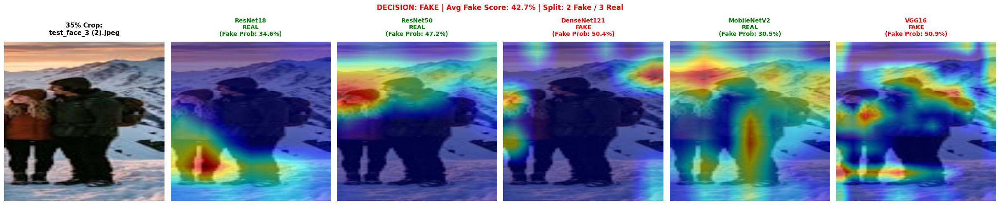


-------------------------------------------------------
RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_3 (2).jpeg
⚙️ MAPPING MODE: INVERTED (Index 0 = REAL, Index 1 = FAKE)
✅ CATEGORY: Human Face Detected!
   Cropping face region (35% margin expansion) & running 5 models...

[ResNet18] Raw Prob[0]: 34.65% | Raw Prob[1]: 65.35% -> Evaluated: FAKE (Fake Prob: 65.35%)
[ResNet50] Raw Prob[0]: 47.16% | Raw Prob[1]: 52.84% -> Evaluated: FAKE (Fake Prob: 52.84%)
[DenseNet121] Raw Prob[0]: 50.44% | Raw Prob[1]: 49.56% -> Evaluated: REAL (Fake Prob: 49.56%)
[MobileNetV2] Raw Prob[0]: 30.47% | Raw Prob[1]: 69.53% -> Evaluated: FAKE (Fake Prob: 69.53%)
[VGG16] Raw Prob[0]: 50.90% | Raw Prob[1]: 49.10% -> Evaluated: REAL (Fake Prob: 49.10%)

---------------- ENSEMBLE SUMMARY ----------------
🗳️  Model Vote Split   : 3 FAKE vs 2 REAL
📊  Average FAKE Score : 57.28%
📊  Average REAL Score : 

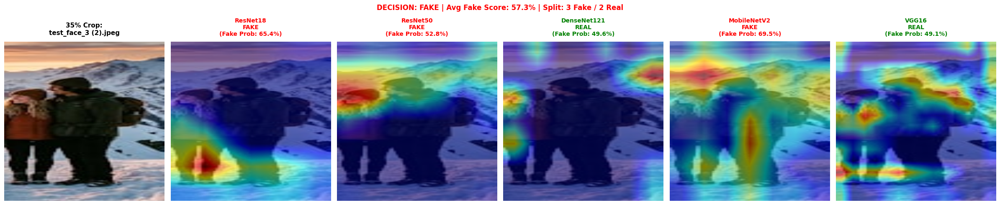

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

👇 Click 'Choose Files' to upload your image:


Saving test_face_14.jpeg to test_face_14.jpeg

-------------------------------------------------------
RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_14.jpeg
⚙️ MAPPING MODE: STANDARD (Index 0 = FAKE, Index 1 = REAL)
ℹ️ CATEGORY: Scenery / Object / Non-Human Image
   Routing to General Scene AI Detector...

🎯 SCENERY DECISION: REAL (Authentic Photo) (97.19% Confidence)



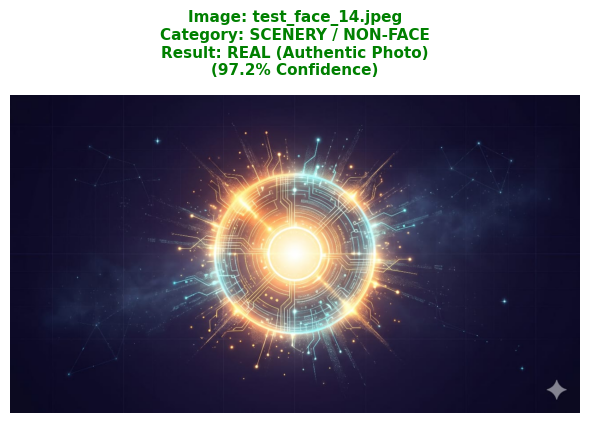


-------------------------------------------------------
RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_14.jpeg
⚙️ MAPPING MODE: INVERTED (Index 0 = REAL, Index 1 = FAKE)
ℹ️ CATEGORY: Scenery / Object / Non-Human Image
   Routing to General Scene AI Detector...

🎯 SCENERY DECISION: REAL (Authentic Photo) (97.19% Confidence)



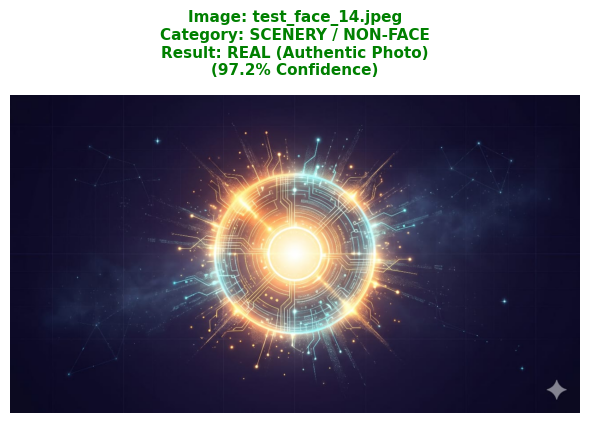

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

👇 Click 'Choose Files' to upload your image:


Saving IMG_0060.jpeg to IMG_0060.jpeg

-------------------------------------------------------
RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)
-------------------------------------------------------

🔍 ANALYZING IMAGE: IMG_0060.jpeg
⚙️ MAPPING MODE: STANDARD (Index 0 = FAKE, Index 1 = REAL)
ℹ️ CATEGORY: Scenery / Object / Non-Human Image
   Routing to General Scene AI Detector...

🎯 SCENERY DECISION: REAL (Authentic Photo) (91.09% Confidence)



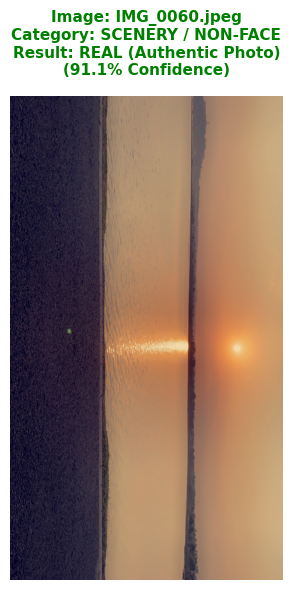


-------------------------------------------------------
RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)
-------------------------------------------------------

🔍 ANALYZING IMAGE: IMG_0060.jpeg
⚙️ MAPPING MODE: INVERTED (Index 0 = REAL, Index 1 = FAKE)
ℹ️ CATEGORY: Scenery / Object / Non-Human Image
   Routing to General Scene AI Detector...

🎯 SCENERY DECISION: REAL (Authentic Photo) (91.09% Confidence)



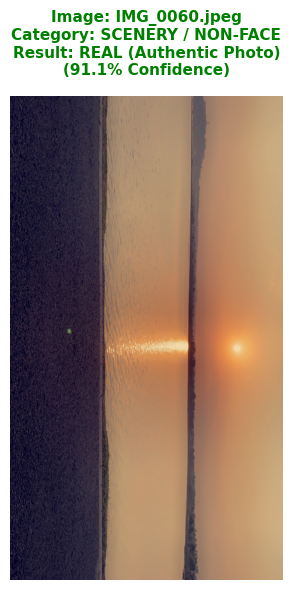

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

👇 Click 'Choose Files' to upload your image:


Saving test_face_9.jpeg to test_face_9.jpeg

-------------------------------------------------------
RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_9.jpeg
⚙️ MAPPING MODE: STANDARD (Index 0 = FAKE, Index 1 = REAL)
ℹ️ CATEGORY: Scenery / Object / Non-Human Image
   Routing to General Scene AI Detector...

🎯 SCENERY DECISION: REAL (Authentic Photo) (86.64% Confidence)



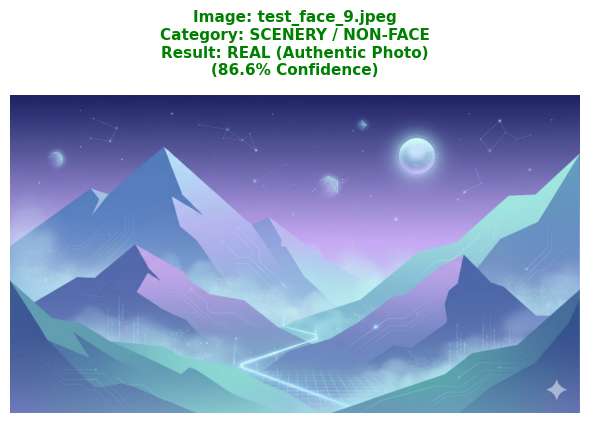


-------------------------------------------------------
RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_9.jpeg
⚙️ MAPPING MODE: INVERTED (Index 0 = REAL, Index 1 = FAKE)
ℹ️ CATEGORY: Scenery / Object / Non-Human Image
   Routing to General Scene AI Detector...

🎯 SCENERY DECISION: REAL (Authentic Photo) (86.64% Confidence)



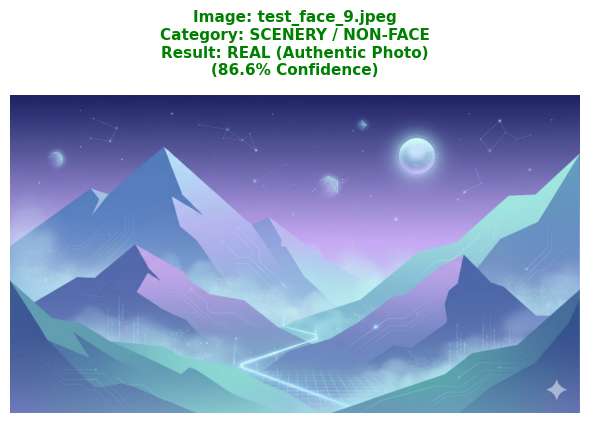

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

👇 Click 'Choose Files' to upload your image:


Saving test_face_2.jpeg to test_face_2 (1).jpeg

-------------------------------------------------------
RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_2 (1).jpeg
⚙️ MAPPING MODE: STANDARD (Index 0 = FAKE, Index 1 = REAL)
✅ CATEGORY: Human Face Detected!
   Cropping face region (35% margin expansion) & running 5 models...

[ResNet18] Raw Prob[0]: 46.55% | Raw Prob[1]: 53.45% -> Evaluated: REAL (Fake Prob: 46.55%)
[ResNet50] Raw Prob[0]: 51.87% | Raw Prob[1]: 48.13% -> Evaluated: FAKE (Fake Prob: 51.87%)
[DenseNet121] Raw Prob[0]: 27.95% | Raw Prob[1]: 72.05% -> Evaluated: REAL (Fake Prob: 27.95%)
[MobileNetV2] Raw Prob[0]: 55.31% | Raw Prob[1]: 44.69% -> Evaluated: FAKE (Fake Prob: 55.31%)
[VGG16] Raw Prob[0]: 64.57% | Raw Prob[1]: 35.43% -> Evaluated: FAKE (Fake Prob: 64.57%)

---------------- ENSEMBLE SUMMARY ----------------
🗳️  Model Vote Split   : 3 FAKE vs 2 REAL
📊  Aver

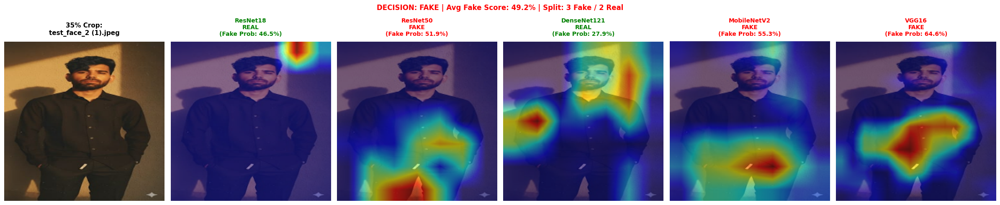


-------------------------------------------------------
RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_face_2 (1).jpeg
⚙️ MAPPING MODE: INVERTED (Index 0 = REAL, Index 1 = FAKE)
✅ CATEGORY: Human Face Detected!
   Cropping face region (35% margin expansion) & running 5 models...

[ResNet18] Raw Prob[0]: 46.55% | Raw Prob[1]: 53.45% -> Evaluated: FAKE (Fake Prob: 53.45%)
[ResNet50] Raw Prob[0]: 51.87% | Raw Prob[1]: 48.13% -> Evaluated: REAL (Fake Prob: 48.13%)
[DenseNet121] Raw Prob[0]: 27.95% | Raw Prob[1]: 72.05% -> Evaluated: FAKE (Fake Prob: 72.05%)
[MobileNetV2] Raw Prob[0]: 55.31% | Raw Prob[1]: 44.69% -> Evaluated: REAL (Fake Prob: 44.69%)
[VGG16] Raw Prob[0]: 64.57% | Raw Prob[1]: 35.43% -> Evaluated: REAL (Fake Prob: 35.43%)

---------------- ENSEMBLE SUMMARY ----------------
🗳️  Model Vote Split   : 2 FAKE vs 3 REAL
📊  Average FAKE Score : 50.75%
📊  Average REAL Score : 

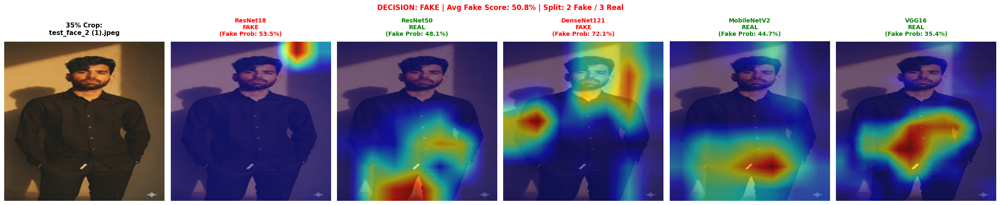

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

Loading Face Detector...
Loading General Scene AI Detector...


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

👇 Click 'Choose Files' to upload your image:


Saving test_12.jpeg to test_12.jpeg

-------------------------------------------------------
RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_12.jpeg
⚙️ MAPPING MODE: STANDARD (Index 0 = FAKE, Index 1 = REAL)
✅ CATEGORY: Human Face Detected!
   Cropping face region (35% margin expansion) & running 5 models...

[ResNet18] Raw Prob[0]: 32.56% | Raw Prob[1]: 67.44% -> Evaluated: REAL (Fake Prob: 32.56%)
[ResNet50] Raw Prob[0]: 47.06% | Raw Prob[1]: 52.94% -> Evaluated: REAL (Fake Prob: 47.06%)
[DenseNet121] Raw Prob[0]: 41.20% | Raw Prob[1]: 58.80% -> Evaluated: REAL (Fake Prob: 41.20%)
[MobileNetV2] Raw Prob[0]: 46.26% | Raw Prob[1]: 53.74% -> Evaluated: REAL (Fake Prob: 46.26%)
[VGG16] Raw Prob[0]: 61.69% | Raw Prob[1]: 38.31% -> Evaluated: FAKE (Fake Prob: 61.69%)

---------------- ENSEMBLE SUMMARY ----------------
🗳️  Model Vote Split   : 1 FAKE vs 4 REAL
📊  Average FAKE Score : 45.

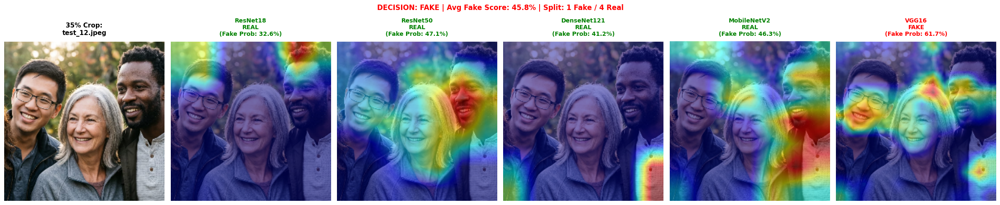


-------------------------------------------------------
RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)
-------------------------------------------------------

🔍 ANALYZING IMAGE: test_12.jpeg
⚙️ MAPPING MODE: INVERTED (Index 0 = REAL, Index 1 = FAKE)
✅ CATEGORY: Human Face Detected!
   Cropping face region (35% margin expansion) & running 5 models...

[ResNet18] Raw Prob[0]: 32.56% | Raw Prob[1]: 67.44% -> Evaluated: FAKE (Fake Prob: 67.44%)
[ResNet50] Raw Prob[0]: 47.06% | Raw Prob[1]: 52.94% -> Evaluated: FAKE (Fake Prob: 52.94%)
[DenseNet121] Raw Prob[0]: 41.20% | Raw Prob[1]: 58.80% -> Evaluated: FAKE (Fake Prob: 58.80%)
[MobileNetV2] Raw Prob[0]: 46.26% | Raw Prob[1]: 53.74% -> Evaluated: FAKE (Fake Prob: 53.74%)
[VGG16] Raw Prob[0]: 61.69% | Raw Prob[1]: 38.31% -> Evaluated: REAL (Fake Prob: 38.31%)

---------------- ENSEMBLE SUMMARY ----------------
🗳️  Model Vote Split   : 4 FAKE vs 1 REAL
📊  Average FAKE Score : 54.25%
📊  Average REAL Score : 45.75%
🎯

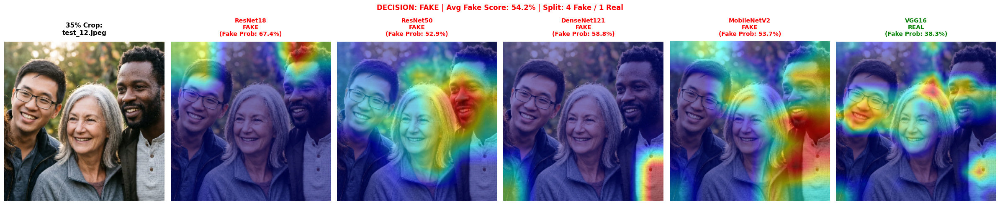

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()

In [ ]:
import os
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from transformers import AutoProcessor, AutoModelForImageClassification
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from google.colab import files

# ---------------------------------------------------------
# 1. SETUP ROUTERS & MODELS
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading Face Detector...")
face_detector = models.detection.fasterrcnn_resnet50_fpn(
    weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
).to(device)
face_detector.eval()

print("Loading General Scene AI Detector...")
scene_processor = AutoProcessor.from_pretrained("umm-maybe/AI-image-detector")
scene_model = AutoModelForImageClassification.from_pretrained("umm-maybe/AI-image-detector").to(device)
scene_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def detect_face_box(pil_image):
    img_tensor = transforms.ToTensor()(pil_image).to(device)
    with torch.no_grad():
        predictions = face_detector([img_tensor])[0]

    person_boxes = [
        box.cpu().numpy() for box, label, score
        in zip(predictions['boxes'], predictions['labels'], predictions['scores'])
        if label == 1 and score > 0.65
    ]
    return person_boxes

# ---------------------------------------------------------
# 2. COMPLETE PIPELINE WITH INVERSION TOGGLE
# ---------------------------------------------------------
def detect_universal_diagnostic(models_dict, image_path, invert_mapping=False, fake_sensitivity_threshold=0.35):
    """
    Evaluates mixed inputs (Faces or Scenery).
    Set invert_mapping=True if your fine-tuning assigned Index 0 = REAL and Index 1 = FAKE.
    """
    if not os.path.exists(image_path):
        print(f"❌ File not found at '{image_path}'.")
        return

    file_name = os.path.basename(image_path)

    if invert_mapping:
        fake_idx, real_idx = 1, 0
        mapping_str = "INVERTED (Index 0 = REAL, Index 1 = FAKE)"
    else:
        fake_idx, real_idx = 0, 1
        mapping_str = "STANDARD (Index 0 = FAKE, Index 1 = REAL)"

    print(f"\n=======================================================")
    print(f"🔍 ANALYZING IMAGE: {file_name}")
    print(f"⚙️ MAPPING MODE: {mapping_str}")
    print(f"=======================================================")

    raw_img = Image.open(image_path).convert('RGB')
    boxes = detect_face_box(raw_img)

    # ---------------------------------------------------------
    # ROUTE A: SCENERY / OBJECT / NON-HUMAN FACE
    # ---------------------------------------------------------
    if len(boxes) == 0:
        print("ℹ️ CATEGORY: Scenery / Object / Non-Human Image")
        print("   Routing to General Scene AI Detector...\n")

        inputs = scene_processor(images=raw_img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = scene_model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)[0]

        pred_idx = torch.argmax(probs).item()
        labels = scene_model.config.id2label
        raw_label = labels[pred_idx].lower()

        if "art" in raw_label or "fake" in raw_label:
            final_result = "FAKE (AI-Generated Scene/Object)"
            label_color = "red"
        else:
            final_result = "REAL (Authentic Photo)"
            label_color = "green"

        confidence = probs[pred_idx].item() * 100
        print(f"🎯 SCENERY DECISION: {final_result} ({confidence:.2f}% Confidence)\n")

        plt.figure(figsize=(6, 6))
        plt.imshow(np.array(raw_img))
        plt.title(f"Image: {file_name}\nCategory: SCENERY / NON-FACE\nResult: {final_result}\n({confidence:.1f}% Confidence)",
                  fontweight='bold', fontsize=11, color=label_color, pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        return

    # ---------------------------------------------------------
    # ROUTE B: HUMAN FACE (5-MODEL ENSEMBLE + 35% CROP)
    # ---------------------------------------------------------
    print("✅ CATEGORY: Human Face Detected!")
    print("   Cropping face region (35% margin expansion) & running 5 models...\n")

    img_np = np.array(raw_img)
    x1, y1, x2, y2 = [int(b) for b in boxes[0]]

    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = int(0.35 * w), int(0.35 * h)

    crop_x1 = max(0, x1 - pad_x)
    crop_y1 = max(0, y1 - pad_y)
    crop_x2 = min(img_np.shape[1], x2 + pad_x)
    crop_y2 = min(img_np.shape[0], y2 + pad_y)

    cropped_face_np = img_np[crop_y1:crop_y2, crop_x1:crop_x2]
    face_pil = Image.fromarray(cropped_face_np)

    img_resized = cv2.resize(cropped_face_np, (224, 224))
    rgb_img = np.float32(img_resized) / 255.0
    input_tensor = eval_transform(face_pil).unsqueeze(0).to(device)

    num_models = len(models_dict)
    fig, axes = plt.subplots(1, num_models + 1, figsize=(4 * (num_models + 1), 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title(f"35% Crop:\n{file_name}", fontweight='bold', fontsize=11, pad=12)
    axes[0].axis('off')

    fake_probs, real_probs, model_votes = [], [], []

    for idx, (model_name, (model, target_layer)) in enumerate(models_dict.items()):
        model.eval()
        for param in model.parameters():
            param.requires_grad = True

        with torch.no_grad():
            output = model(input_tensor)
            probs = F.softmax(output, dim=1)[0]

            p_fake = probs[fake_idx].item()
            p_real = probs[real_idx].item()

            fake_probs.append(p_fake)
            real_probs.append(p_real)

            pred_label = "FAKE" if p_fake > p_real else "REAL"
            model_votes.append(pred_label)

        print(f"[{model_name}] Raw Prob[0]: {probs[0].item()*100:.2f}% | Raw Prob[1]: {probs[1].item()*100:.2f}% -> Evaluated: {pred_label} (Fake Prob: {p_fake*100:.2f}%)")

        label_color = 'red' if pred_label == 'FAKE' else 'green'
        target_class_idx = fake_idx if pred_label == 'FAKE' else real_idx
        targets = [ClassifierOutputTarget(target_class_idx)]

        with GradCAM(model=model, target_layers=target_layer) as cam:
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax = axes[idx + 1]
        ax.imshow(visualization)
        ax.set_title(
            f"{model_name}\n{pred_label}\n(Fake Prob: {p_fake*100:.1f}%)",
            fontweight='bold',
            fontsize=10,
            color=label_color,
            pad=10
        )
        ax.axis('off')

    avg_fake_prob = np.mean(fake_probs) * 100
    avg_real_prob = np.mean(real_probs) * 100
    fake_count = model_votes.count('FAKE')
    real_count = model_votes.count('REAL')

    if avg_fake_prob >= (fake_sensitivity_threshold * 100):
        ensemble_decision = "FAKE"
        ensemble_color = "red"
    else:
        ensemble_decision = "REAL"
        ensemble_color = "green"

    print("\n---------------- ENSEMBLE SUMMARY ----------------")
    print(f"🗳️  Model Vote Split   : {fake_count} FAKE vs {real_count} REAL")
    print(f"📊  Average FAKE Score : {avg_fake_prob:.2f}%")
    print(f"📊  Average REAL Score : {avg_real_prob:.2f}%")
    print(f"🎯  FINAL DECISION    : {ensemble_decision} ({max(avg_fake_prob, avg_real_prob):.2f}% Confidence)")
    print("--------------------------------------------------\n")

    title_text = f"DECISION: {ensemble_decision} | Avg Fake Score: {avg_fake_prob:.1f}% | Split: {fake_count} Fake / {real_count} Real"
    plt.suptitle(title_text, fontsize=12, fontweight='bold', color=ensemble_color, y=1.03)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. INTERACTIVE DIAGNOSTIC RUNNER
# ---------------------------------------------------------
def run_interactive_diagnostic():
    print("👇 Click 'Choose Files' to upload your image:")
    uploaded = files.upload()

    if not uploaded:
        print("❌ No file uploaded.")
        return

    file_name = list(uploaded.keys())[0]
    file_path = f"/content/{file_name}"

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 1: Standard Index Mapping (Index 0 = FAKE, Index 1 = REAL)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=False)

    print("\n-------------------------------------------------------")
    print("RUNNING TEST 2: Inverted Index Mapping (Index 0 = REAL, Index 1 = FAKE)")
    print("-------------------------------------------------------")
    detect_universal_diagnostic(trained_models_dict, file_path, invert_mapping=True)

# Run interactive diagnostic
run_interactive_diagnostic()